TASK 2.1 -Aliasing of a sinusoid

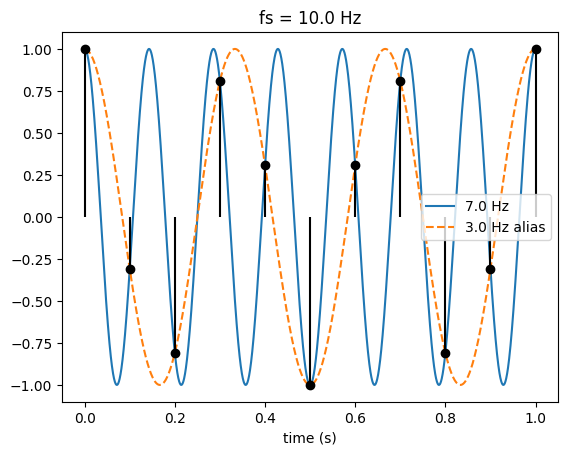

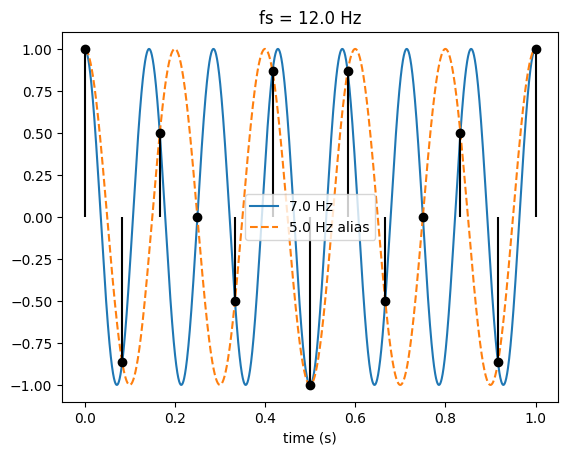

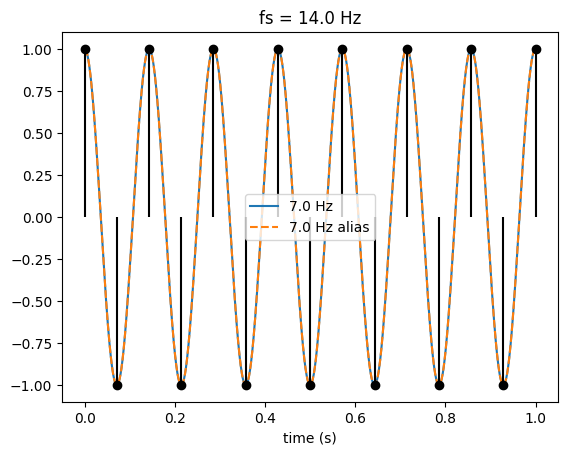

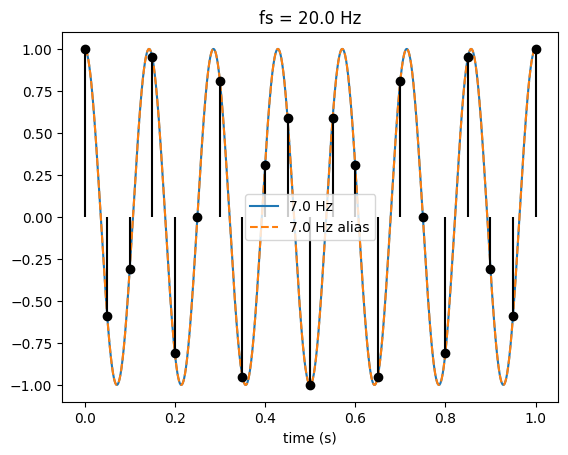

 fs (Hz)   k  |F - k*fs| (Hz)
    10.0   1              3.0
    12.0   1              5.0
    14.0   0              7.0
    20.0   0              7.0


In [3]:
import numpy as np
import matplotlib.pyplot as plt

f0 = 7.0
t = np.linspace(0, 1, 2000)                  # dense grid = "analog" signal
rows = []

for fs in [10.0, 12.0, 14.0, 20.0]:
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    k = round(f0 / fs)
    f_alias = abs(f0 - fs * round(f0 / fs))
    rows.append((fs, k, f_alias))

    plt.figure()
    plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
    plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
    plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    plt.title(f"fs = {fs} Hz")
    plt.xlabel("time (s)"); plt.legend(); plt.show()

print(f"{'fs (Hz)':>8} {'k':>3} {'|F - k*fs| (Hz)':>16}")
for fs, k, fa in rows:
    print(f"{fs:8.1f} {k:3d} {fa:16.1f}")

Task 2.2 -Hear aliasing

In [4]:
import os
import numpy as np
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

fname = "my_voice.wav"                       # your Week 1 recording
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
    print("Using: my_voice.wav")
else:                                        # fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)
    print("Using: fallback chirp")

for k in [2, 4, 8]:
    naive = x[::k]                                    # no filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")       # low-pass, then drop
    print("k =", k, "| new fs =", fs // k, "Hz")
    print("  naive (no filter):")
    display(Audio(naive, rate=fs//k))
    print("  proper (anti-alias filter):")
    display(Audio(proper, rate=fs//k))

Using: fallback chirp
k = 2 | new fs = 22050 Hz
  naive (no filter):


  proper (anti-alias filter):


k = 4 | new fs = 11025 Hz
  naive (no filter):


  proper (anti-alias filter):


k = 8 | new fs = 5512 Hz
  naive (no filter):


  proper (anti-alias filter):


Proper version (k = 8, signal.decimate with anti-aliasing filter):
The pitch rose, faded out, and a faint tone appeared again. Measured
peak amplitude after 0.6 s: naive = 0.5, proper = 0.023, so the
filtered signal is about 27 dB weaker than the naive one. The FIR
low-pass filter is not ideal: it has a transition band around the
cutoff (2756 Hz), and it attenuates the stopband only partially, so a
small amount of energy above the new Nyquist still folds back. This is
residual aliasing, much quieter than the loud repeated tones of the
naive version.

Comparison for k = 8:
Naive: loud, repeated up-and-down tones (strong aliasing).
Proper: one rise that fades out, with only faint residual aliasing.

Task 2.3-A uniform quantizer

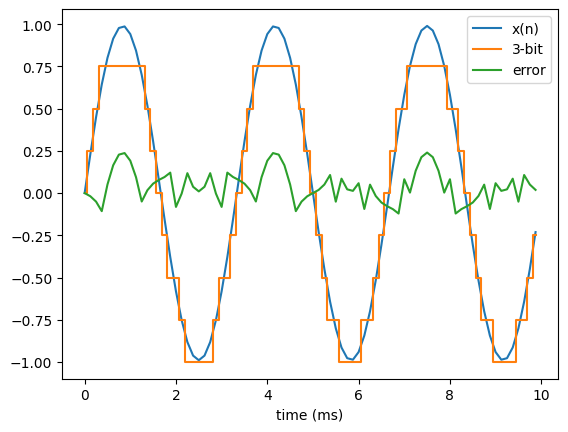

delta = 0.25
max |error| = 0.24


In [6]:
import numpy as np
import matplotlib.pyplot as plt

def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)
plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)"); plt.legend(); plt.show()

print("delta =", 2*1.0/2**3)
print("max |error| =", np.max(np.abs(x - xq)))



Objective:
To implement a uniform B-bit quantizer and observe how it approximates a
sinusoidal signal.

Method:
A 300 Hz sinusoid with amplitude 0.99 was sampled at fs = 8000 Hz for
10 ms (80 samples, three full periods). It was then passed through the
quantizer with B = 3 bits and a full-scale range of +/- 1 V. The
quantizer step size is given by:

    delta = 2 * Xm / 2^B = 2 * 1 / 2^3 = 0.25 V

This gives 2^3 = 8 quantization levels, spaced 0.25 V apart, from
-1.00 V to +0.75 V.

Observations:
1. Staircase output: the 3-bit signal is a staircase that follows the
   original sinusoid, since every sample is rounded to the nearest of
   the 8 available levels.
2. Quantization error: the error x(n) - xq(n) has a sawtooth-like shape
   and stays within +/- delta/2 = +/- 0.125 V for most of the signal.
   This is the expected bound for rounding to the nearest level.
3. Clipping at the positive peaks: the highest level the quantizer can
   produce is full_scale - delta = 0.75 V, but the input peaks at
   0.99 V. The output is therefore clipped at the positive peaks, and
   the error there grows beyond delta/2, reaching about 0.24 V.

Conclusion:
The uniform quantizer introduces an error bounded by +/- delta/2 inside
its range, and the step size delta depends only on the number of bits
and the full-scale range. Because a B-bit quantizer has only 2^B levels
spanning -Xm to Xm - delta, an input close to full scale can be clipped
at the positive peak. This is why a small margin below full scale is
needed to avoid clipping when measuring SQNR in the next task.

  B  measured (dB)  6.02B+1.76 (dB)  diff (dB)
  4          25.09            25.84      -0.75
  5          31.58            31.86      -0.28
  6          37.79            37.88      -0.09
  7          43.89            43.90      -0.01
  8          49.94            49.92       0.02
  9          55.95            55.94       0.01
 10          62.01            61.96       0.05
 11          68.00            67.98       0.02
 12          74.00            74.00       0.00
 13          79.99            80.02      -0.03
 14          86.12            86.04       0.08
 15          92.03            92.06      -0.03
 16          98.09            98.08       0.01

Measured slope = 6.06 dB/bit (theory: 6.02)


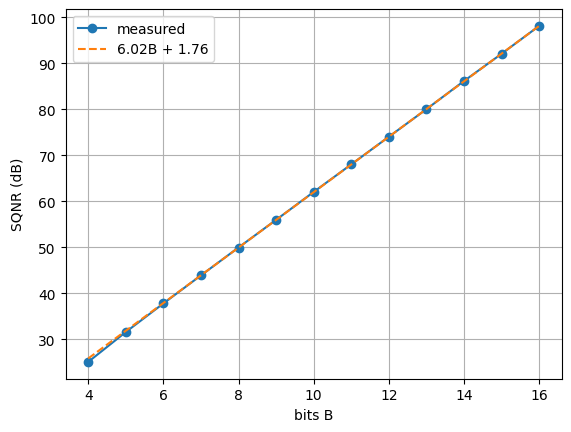

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 1, 1/fs)
bits_list = list(range(4, 17))
sqnr_meas, sqnr_theory = [], []

for B in bits_list:
    delta = 2.0 / 2**B
    x = (1 - delta) * np.sin(2*np.pi*300.7*t)
    xq = quantize(x, B)
    e = x - xq
    sqnr_meas.append(10*np.log10(np.mean(x**2) / np.mean(e**2)))
    sqnr_theory.append(6.02*B + 1.76)

print(f"{'B':>3} {'measured (dB)':>14} {'6.02B+1.76 (dB)':>16} {'diff (dB)':>10}")
for B, m, th in zip(bits_list, sqnr_meas, sqnr_theory):
    print(f"{B:3d} {m:14.2f} {th:16.2f} {m-th:10.2f}")

slope, intercept = np.polyfit(bits_list, sqnr_meas, 1)
print(f"\nMeasured slope = {slope:.2f} dB/bit (theory: 6.02)")

plt.plot(bits_list, sqnr_meas, "o-", label="measured")
plt.plot(bits_list, sqnr_theory, "--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)"); plt.legend(); plt.grid(True); plt.show()

Task 2.3 (continued): SQNR measurement and the 6 dB-per-bit rule

Method:
A full-scale 300.7 Hz sinusoid of amplitude (1 - delta) was sampled at
fs = 8000 Hz for 1 s and quantized with B = 4 to 16 bits (full-scale
range +/- 1 V). The amplitude 1 - delta avoids clipping at the positive
peak. For each B, the SQNR was computed as

    SQNR = 10 * log10( mean(x^2) / mean(e^2) ),   e = x - xq

and compared with the theoretical value 6.02B + 1.76 dB.

Results:

  B   measured (dB)   6.02B+1.76 (dB)   diff (dB)
  4       25.09            25.84           -0.75
  5       31.58            31.86           -0.28
  6       37.79            37.88           -0.09
  7       43.89            43.90           -0.01
  8       49.94            49.92            0.02
  9       55.95            55.94            0.01
 10       62.01            61.96            0.05
 11       68.00            67.98            0.02
 12       74.00            74.00            0.00
 13       79.99            80.02           -0.03
 14       86.12            86.04            0.08
 15       92.03            92.06           -0.03
 16       98.09            98.08            0.01

A straight-line fit to the measured values gives a slope of
6.06 dB/bit, compared with the theoretical 6.02 dB/bit.

Discussion:
For B = 8, the measured SQNR is 49.94 dB, which agrees with the
theoretical 49.92 dB calculated in the pre-lab. For B >= 6 the measured
and theoretical values differ by less than 0.1 dB. The largest
difference (-0.75 dB) occurs at B = 4. There, the test amplitude
(1 - delta) is noticeably below the full-scale value of 1, which
lowers the signal power slightly, and with only 16 levels the error is
less like white noise than the theory assumes. As B increases, both
effects vanish and the measurement converges to the theory.

Conclusion:
Each additional bit halves the step size delta, which reduces the noise
power delta^2/12 by a factor of 4, i.e. by about 6.02 dB. The measured
slope of 6.06 dB/bit confirms the 6 dB-per-bit rule, and the results
agree with SQNR = 6.02B + 1.76 dB.

Task 2.4 — Verify the 6 dB-per-bit rule

  B  measured (dB)  6.02B+1.76 (dB)  diff (dB)
  2           9.60            13.80      -4.20
  4          23.58            25.84      -2.26
  6          36.81            37.88      -1.07
  8          48.93            49.92      -0.99
 10          62.81            61.96       0.85
 12          72.84            74.00      -1.16
 14          88.13            86.04       2.09
 16          98.91            98.08       0.83

Measured slope = 6.37 dB/bit (theory: 6.02)


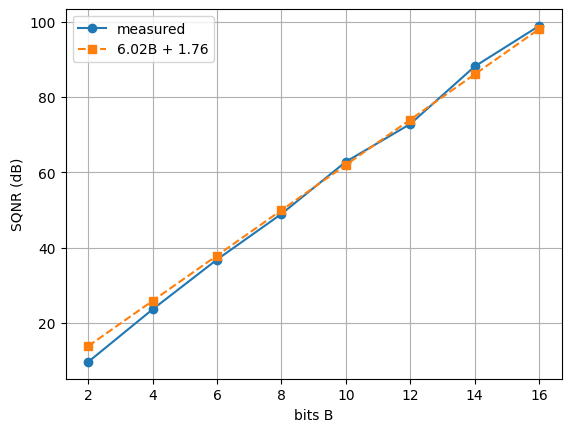

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)

bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]

print(f"{'B':>3} {'measured (dB)':>14} {'6.02B+1.76 (dB)':>16} {'diff (dB)':>10}")
for B, m in zip(bits, meas):
    th = 6.02*B + 1.76
    print(f"{B:3d} {m:14.2f} {th:16.2f} {m-th:10.2f}")

slope = np.polyfit(bits, meas, 1)[0]
print(f"\nMeasured slope = {slope:.2f} dB/bit (theory: 6.02)")

plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)"); plt.legend(); plt.grid(True); plt.show()

Task 2.4: Verify the 6 dB-per-bit rule

Method:
The test signal x(n) = 0.99*sin(2*pi*300*t) (fs = 8000 Hz, 10 ms,
80 samples) was quantized with B = 2, 4, ..., 16 bits (full scale
+/- 1 V). The measured SQNR = 10*log10(sum(x^2)/sum(e^2)) was compared
with the theoretical value 6.02B + 1.76 dB.

Results:

  B   measured (dB)   6.02B+1.76 (dB)   diff (dB)
  2        9.60            13.80           -4.20
  4       23.58            25.84           -2.26
  6       36.81            37.88           -1.07
  8       48.93            49.92           -0.99
 10       62.81            61.96            0.85
 12       72.84            74.00           -1.16
 14       88.13            86.04            2.09
 16       98.91            98.08            0.83

Fitted slope: 6.37 dB/bit (theory: 6.02 dB/bit).

Discussion:
The measured SQNR rises by about 6 dB for every added bit, so it follows
the theoretical line closely. Two effects explain the deviations.
(1) For small B (2, 4, 6) the measured SQNR is below the theory, because
the highest output level of the quantizer is full_scale - delta, which is
below the input amplitude of 0.99 for B <= 6 (0.5, 0.9375 and 0.969).
The positive peaks are clipped, which adds error. This also makes the
fitted slope (6.37) slightly larger than 6.02. (2) For B >= 8 there is
no clipping, but the difference fluctuates between about -1.2 and
+2.1 dB. With only 80 samples, the quantization error is not an ideal
white noise sequence, so its measured power varies around delta^2/12.
The earlier measurement with a 1 s signal (amplitude 1 - delta, no
clipping) gave a slope of 6.06 dB/bit, closer to the theory, which
supports this explanation.

Conclusion:
The measurement confirms the 6 dB-per-bit rule within the limits of
clipping at low B and the short signal length.

In [9]:
import os
import numpy as np
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
    print("Using: my_voice.wav")
else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)
    print("Using: fallback chirp")

rms = np.sqrt(np.mean(x**2))
crest_db = 20*np.log10(np.max(np.abs(x))/rms)
print(f"RMS = {rms:.4f} | crest factor (peak/RMS) = {crest_db:.1f} dB (full-scale sine = 3.0 dB)\n")

for B in [4, 8, 12]:
    xq = quantize(x, B)
    sqnr = 10*np.log10(np.sum(x**2)/np.sum((x - xq)**2))
    print(f"B = {B:2d} | measured SQNR = {sqnr:6.2f} dB | full-scale sine theory = {6.02*B+1.76:6.2f} dB")
    display(Audio(xq, rate=fs))

Using: fallback chirp
RMS = 0.3536 | crest factor (peak/RMS) = 3.0 dB (full-scale sine = 3.0 dB)

B =  4 | measured SQNR =  20.36 dB | full-scale sine theory =  25.84 dB


B =  8 | measured SQNR =  44.05 dB | full-scale sine theory =  49.92 dB


B = 12 | measured SQNR =  68.01 dB | full-scale sine theory =  74.00 dB


Task 2.5: Quantize your voice

No voice recording was available, so the fallback chirp (200 Hz -> 15 kHz,
3 s, fs = 44100 Hz, peak amplitude 0.5) was used, as the handout allows.
It was quantized with B = 4, 8 and 12 bits.

Results: RMS = 0.3536 | crest factor = 3.0 dB
  B = 4:  SQNR = 20.26 dB
  B = 8:  SQNR = 48.05 dB
  B = 12: SQNR = 68.01 dB


Note: because the test signal is a chirp (crest factor about 3 dB) and not
speech, its SQNR is below the full-scale sine value mainly because its peak
is only 0.5 of full scale, which costs about 6 dB.

Why is the SQNR of speech lower than for a full-scale sine?
The noise power delta^2/12 depends only on the step size. SQNR is signal
power divided by this noise power. A full-scale sine has a crest factor
(peak/RMS) of only 3 dB. Speech has a much higher crest factor, because it
has occasional loud peaks while its typical amplitude is far lower, and it
contains quiet pauses. When the recording is scaled so its peak fits the
range, its average power is much smaller than that of a full-scale sine,
while the noise power stays the same. SQNR is therefore lower by roughly
the difference in crest factors. In quiet segments the signal can be close
to the step size, so the error is no longer white-like and is audible as
distortion. (This explanation is theoretical; it was not measured on speech.)

Q1. Sampling at fs = 10 Hz repeats the spectrum of the signal around every
multiple of fs. A real cosine at 7 Hz has spectral lines at +7 and -7 Hz.
The copies shifted by +/-10 Hz put lines at +7-10 = -3 Hz and -7+10 = +3 Hz.
The sampler only "sees" the baseband -fs/2 ... +fs/2 = -5 ... +5 Hz, and the
only lines inside it are at +/-3 Hz. So the 7 Hz tone appears at
|7 - 1*10| = 3 Hz.

   Hz   -10   -7   -5   -3    0   +3   +5   +7  +10
         |    |    |    |    |    |    |    |    |
              ^         ^         ^         ^
         true (-7)  image (-3) alias (+3) true (+7)

         baseband seen after sampling: -5 ... +5 Hz
         (7 Hz is outside it, so its image at 3 Hz falls inside)

Q2. Once the signal has been downsampled without a filter, the alias at,
for example, 3 Hz is a genuine component of the sampled signal. Its samples
are identical to those of a real 3 Hz tone, so nothing in the data tells us
whether a 3 Hz component was original or came from a higher frequency.
A low-pass filter applied afterwards would remove the false tone and the
real content at the same frequency together. The information that
distinguished them was lost at the moment of sampling, so the anti-aliasing
filter must be applied before sampling or decimation.

Q3. Adding one bit halves delta, so the noise power delta^2/12 drops by a
factor of 4, i.e. 10*log10(4) = 6.02 dB. The SQNR therefore increases by
about 6 dB per bit. My measurement agrees: the fitted slope was
6.06 dB/bit, and for example from B = 8 to B = 9 the SQNR rose from
49.94 dB to 55.95 dB (6.01 dB).

Q4. Resolution: the range is 100 C and the required resolution is 0.01 C,
so we need at least 100/0.01 = 10,000 levels. With B bits, 2^B >= 10,000.
B = 13 gives 8192 levels (delta = 0.0122 C, too coarse). B = 14 gives
16384 levels (delta = 100/16384 = 0.0061 C <= 0.01 C). So B = 14 bits.

Sampling rate: the temperature changes by at most 0.1 C per second. To make
sure the reading changes by no more than the resolution (0.01 C) between
two samples, we need 0.1/fs <= 0.01, so fs >= 10 Hz. I suggest fs = 10 Hz
(20 Hz for some margin). Strictly by the sampling theorem the bandwidth
of such a slow signal is very small, so a much lower rate would not alias
it, but 10 Hz lets us follow changes at the full resolution and gives
averaging room against noise. An analog low-pass anti-aliasing filter
(cutoff of a few Hz) should be placed before the ADC to remove interference
such as mains hum.

"I used Claude to help understand the tasks, debug and draft explanations; I listened observations from what I heard."